# Atividade 2
---
**Objetivo**

Aplicar técnicas de filtragem espacial para suavização, remoção de ruído e detecção de bordas
em imagens reais coletadas pelo próprio aluno, analisando criticamente o tipo de degradação
presente e justificando a escolha do filtro mais adequado com base nos fundamentos teóricos do
pré-processamento de imagens.

## Preparação do ambiente
---
utilzaremos as bibliotecas
- opencv
- matplotlib

In [14]:
import cv2
import matplotlib.pyplot as plt
import os
import numpy as np

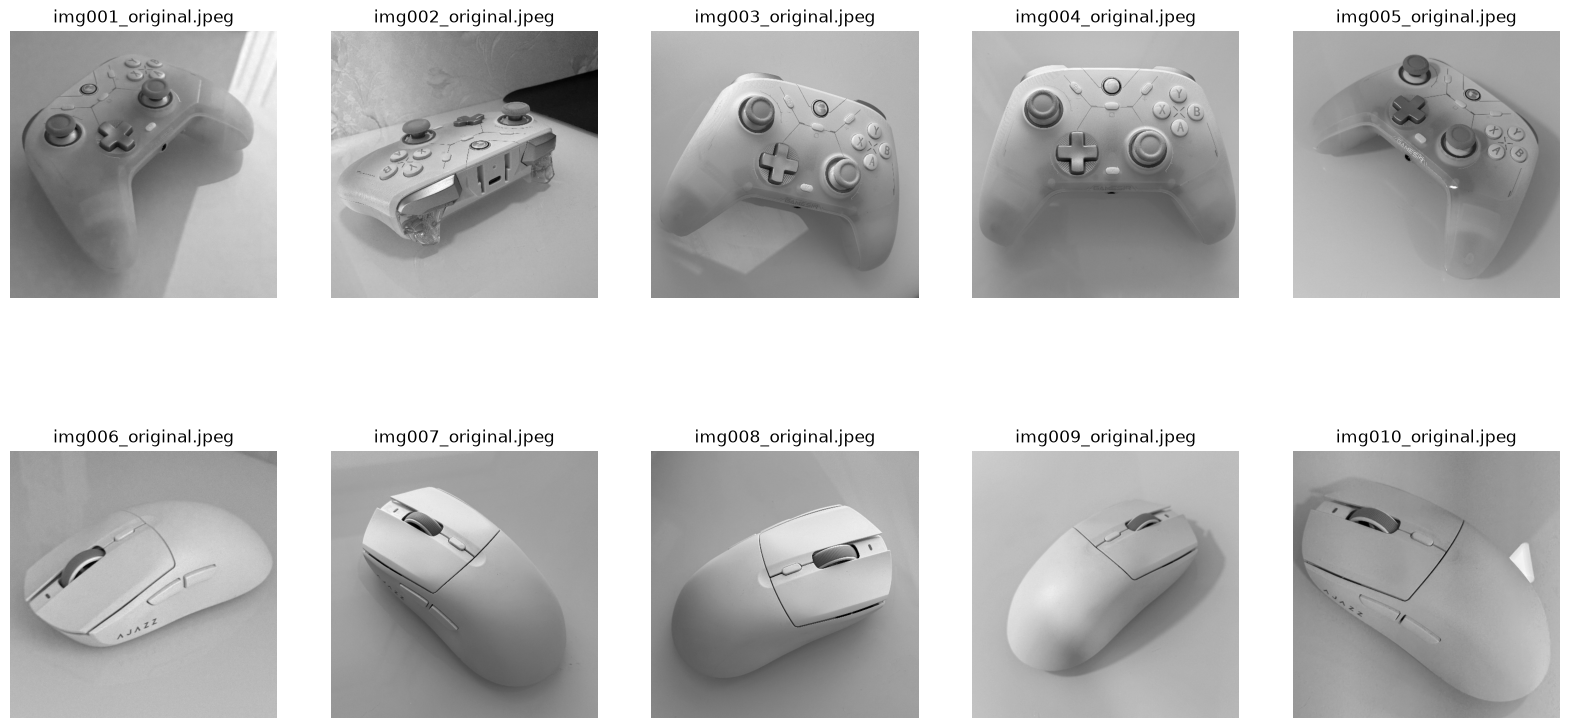

In [51]:
dir_A = "dataset/classe-A"
dir_B = "dataset/classe-B"

images_class_A = os.listdir(dir_A)
images_class_B = os.listdir(dir_B)

fig, axs = plt.subplots(2, 5, figsize=(20, 10))
for idx, name in enumerate(images_class_A):
    img = cv2.imread(os.path.join(dir_A, name), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (512, 512))
    axs[0][idx].imshow(img, cmap="gray")
    axs[0][idx].set_title(name)
    axs[0][idx].axis("off")

for idx, name in enumerate(images_class_B):
    img = cv2.imread(os.path.join(dir_B, name), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (512, 512))
    axs[1][idx].imshow(img, cmap="gray")
    axs[1][idx].set_title(name)
    axs[1][idx].axis("off")


## Parte 1: Selecao de Imagens
---
**Criterios**: imagens que apresentam pelo menos uma das caracteristicas abaixo
- Granulacao
- Pequenas variacoes aleatorias de intensidade
- Compressao visivel
- Pequeno nivel de ruido

As imagens escolhidas foram:

**classe A**:
- img01 -> pequenas variacoes aleatorias de intensidade ( causa: baixa luminosidade e mesa de vidro )
- img03 -> pequeno nivel de ruido ( causa: foto tirada contra o sol )

**classe B**:
- img06 -> pequeno nivel de ruido ( causa: foto tirada contra o sol )
- img10 -> pequenas variacoes aleatorias de intensidade ( causa: vidro da mesa refletindo luz do sol )

## Parte 2: Aplicacao de filtros de suavizacao
---

**Metodo**: Aplicar os seguintes filtros com os respectivos parametros para cada imagem
- Filtro Medio
    - Kernel 3x3
    - Kernel 5x5
- Filtro Gaussiano
    - 𝜎 = 1
    - 𝜎 = 3
- Filtro da Mediana
    - Kernel 3x3
    - Kernel 5x5

In [ ]:
def aplicar_filtros(img):
    img = cv2.resize(img, (512, 512))

    fig, axs = plt.subplots(3, 2, figsize=(14, 8), constrained_layout=True)

    axs[0][0].set_title("Filtro Medio com kernel 3x3")
    axs[0][0].imshow(cv2.blur(img, ksize=(3, 3)), cmap="gray") # Filtro Medio com kernel 3x3
    axs[0][0].axis("off")
    axs[0][1].set_title("Filtro Medio com kernel 5x5")
    axs[0][1].imshow(cv2.blur(img, ksize=(5, 5)), cmap="gray") # Filtro Medio com kernel 5x5
    axs[0][1].axis("off")


    axs[1][0].set_title("Filtro Gaussiano com sigma = 1")
    axs[1][0].imshow(cv2.GaussianBlur(img, ksize=(0, 0), sigmaX=1), cmap="gray") # Filtro Gaussiano com 𝜎 = 1
    axs[1][0].axis("off")
    axs[1][1].set_title("Filtro Gaussiano com sigma = 3")
    axs[1][1].imshow(cv2.GaussianBlur(img, ksize=(0, 0), sigmaX=3), cmap="gray") # Filtro Gaussiano com 𝜎 = 3
    axs[1][1].axis("off")


    axs[2][0].set_title("Filtro da Mediana com kernel 3x3")
    axs[2][0].imshow(cv2.medianBlur(img, ksize=3), cmap="gray") # Filtro da Mediana com kernel 3x3
    axs[2][0].axis("off")
    axs[2][1].set_title("Filtro da Mediana com kernel 5x5")
    axs[2][1].imshow(cv2.medianBlur(img, ksize=5), cmap="gray") # Filtro da Mediana com kernel 5x5
    axs[2][1].axis("off")

    return {    
        "original": img,
        "filtro medio 3x3": cv2.blur(img, ksize=(3, 3)),
        "filtro medio 5x5": cv2.blur(img, ksize=(5, 5)),
        "filtro gaussiano sigma 1": cv2.GaussianBlur(img, ksize=(0, 0), sigmaX=1),
        "filtro gaussiano sigma 3": cv2.GaussianBlur(img, ksize=(0, 0), sigmaX=3),
        "filtro mediana 3x3": cv2.medianBlur(img, ksize=3),
        "filtro mediana 5x5": cv2.medianBlur(img, ksize=5)
    }

SyntaxError: invalid syntax (1097775865.py, line 30)

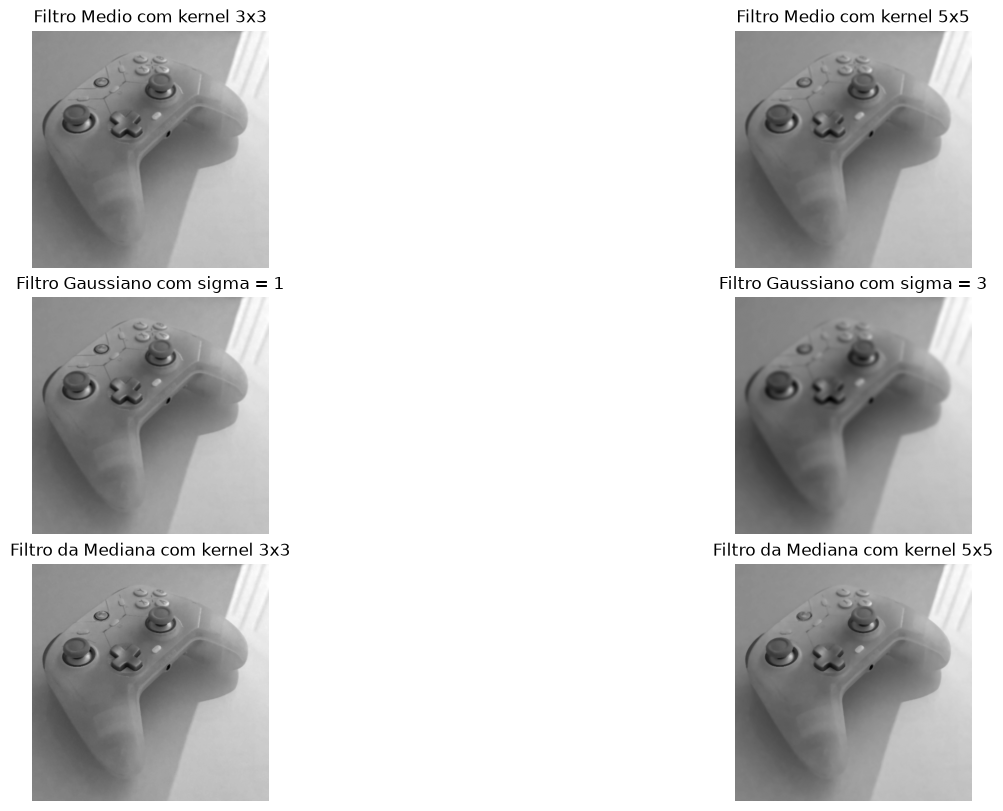

In [53]:
# para img01

aplicar_filtros(cv2.imread(os.path.join(dir_A, "img001_original.jpeg"), cv2.IMREAD_GRAYSCALE))